<a href="https://colab.research.google.com/github/Neeraj486-eng/Text-classification/blob/main/IR_task_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn requests

Dataset loaded successfully
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Training feature shape: (4135, 5000)
Testing feature shape: (1034, 5000)

Training: Decision Tree
              precision    recall  f1-score   support

         Ham       0.97      0.99      0.98       903
        Spam       0.90      0.79      0.85       131

    accuracy                           0.96      1034
   macro avg       0.94      0.89      0.91      1034
weighted avg       0.96      0.96      0.96      1034


Training: KNN
              precision    recall  f1-score   support

         Ham     

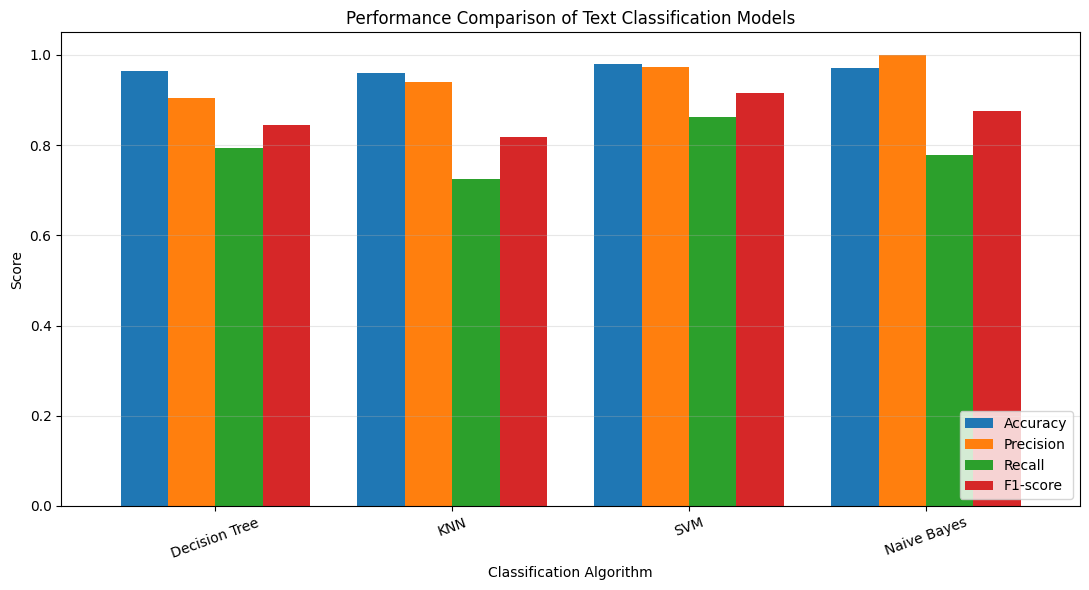

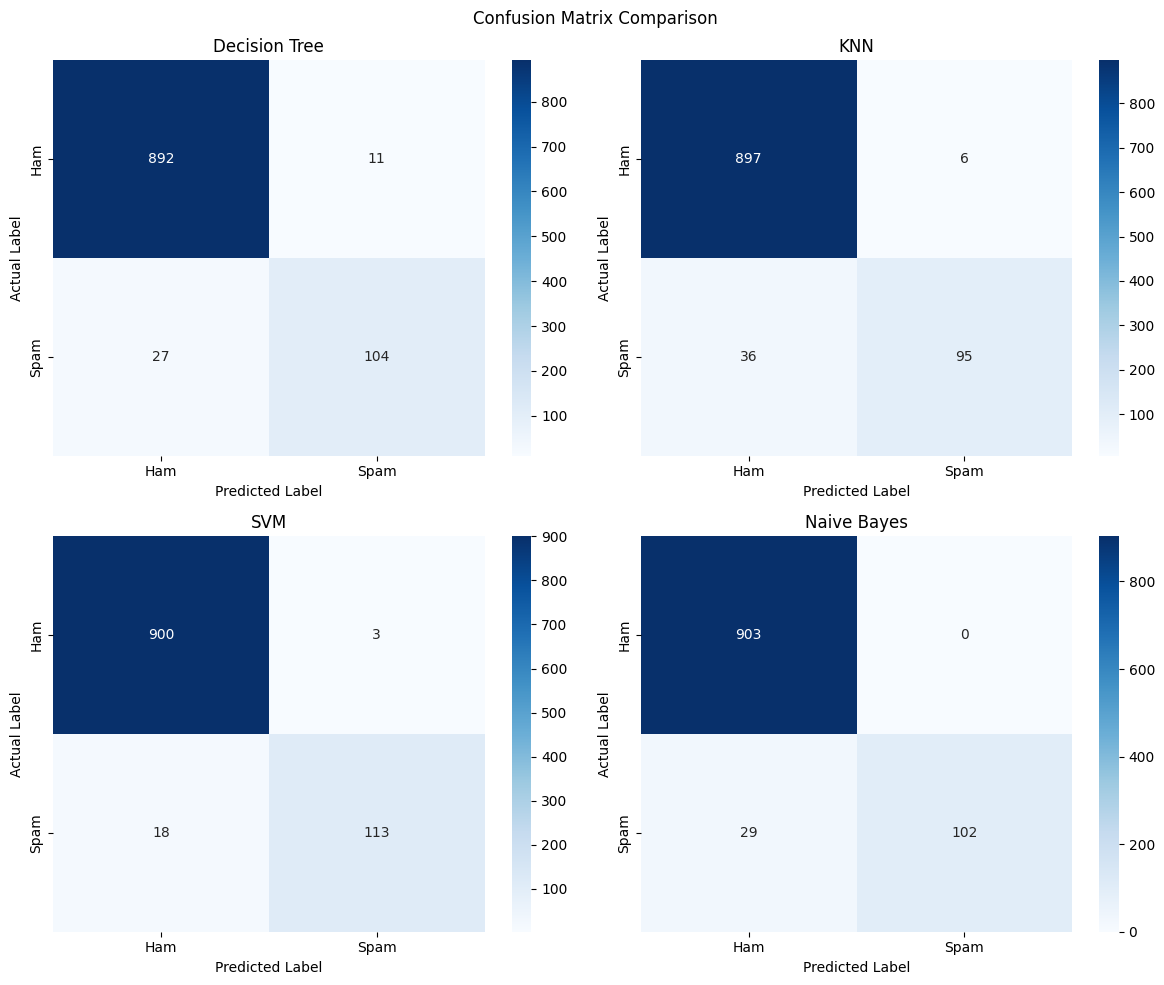


========== BEST MODEL ==========
Algorithm: SVM
Accuracy: 0.9797
Precision: 0.9741
Recall: 0.8626
F1-score: 0.915

========== WHAT-IF EXPERIMENT ==========
 C value  Accuracy  Precision   Recall  F1-score
    0.01  0.873308   0.000000 0.000000  0.000000
    0.10  0.966151   0.980000 0.748092  0.848485
    1.00  0.979691   0.974138 0.862595  0.914980
   10.00  0.978723   0.965812 0.862595  0.911290


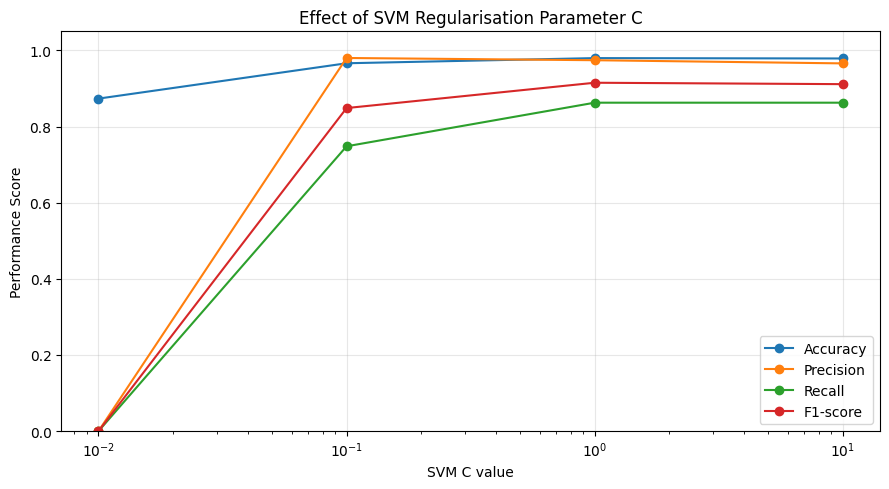


Experiment completed successfully!
Results and graphs have been saved.


In [2]:

# ============================================================
# COMPARATIVE STUDY OF FOUR TEXT CLASSIFICATION ALGORITHMS
# Decision Tree, KNN, SVM and Naive Bayes
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile
import io

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("SMSSpamCollection") as f:
        df = pd.read_csv(
            f,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

print("Dataset loaded successfully")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

# ------------------------------------------------------------
# 2. DATA PREPROCESSING
# ------------------------------------------------------------

# Remove missing values and duplicate messages
df = df.dropna()
df = df.drop_duplicates(subset="message")

# Convert class labels into numerical values
df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

X = df["message"]
y = df["label"]

# ------------------------------------------------------------
# 3. TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# 4. TF-IDF FEATURE EXTRACTION
# ------------------------------------------------------------

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 1),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("\nTraining feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

# ------------------------------------------------------------
# 5. INITIALISE CLASSIFICATION MODELS
# ------------------------------------------------------------

models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=30,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute"
    ),

    "SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    ),

    "Naive Bayes": MultinomialNB(
        alpha=1.0
    )
}

# ------------------------------------------------------------
# 6. TRAIN AND EVALUATE MODELS
# ------------------------------------------------------------

results = []
predictions = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Ham", "Spam"],
        zero_division=0
    ))

# ------------------------------------------------------------
# 7. COMPARATIVE PERFORMANCE TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n========== COMPARATIVE RESULTS ==========")
print(
    results_df.to_string(
        index=False,
        formatters={
            col: "{:.4f}".format
            for col in ["Accuracy", "Precision", "Recall", "F1-score"]
        }
    )
)

# ------------------------------------------------------------
# 8. PERFORMANCE COMPARISON GRAPH
# ------------------------------------------------------------

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

results_df.set_index("Algorithm")[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05),
    width=0.8
)

plt.title("Performance Comparison of Text Classification Models")
plt.ylabel("Score")
plt.xlabel("Classification Algorithm")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("performance_comparison.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 9. CONFUSION MATRICES
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(
    axes.flatten(), predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 10. IDENTIFY BEST-PERFORMING MODEL
# ------------------------------------------------------------

best_model = results_df.loc[
    results_df["F1-score"].idxmax()
]

print("\n========== BEST MODEL ==========")
print("Algorithm:", best_model["Algorithm"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-score:", round(best_model["F1-score"], 4))

# ------------------------------------------------------------
# 11. WHAT-IF EXPERIMENT
# Change SVM regularisation parameter C
# ------------------------------------------------------------

what_if_results = []

for c_value in [0.01, 0.1, 1.0, 10.0]:

    svm_model = LinearSVC(
        C=c_value,
        random_state=42,
        max_iter=5000
    )

    svm_model.fit(X_train_tfidf, y_train)

    pred = svm_model.predict(X_test_tfidf)

    what_if_results.append({
        "C value": c_value,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, zero_division=0
        )
    })

what_if_df = pd.DataFrame(what_if_results)

print("\n========== WHAT-IF EXPERIMENT ==========")
print(what_if_df.to_string(index=False))

# Plot what-if experiment
what_if_df.plot(
    x="C value",
    y=["Accuracy", "Precision", "Recall", "F1-score"],
    marker="o",
    figsize=(9, 5)
)

plt.title("Effect of SVM Regularisation Parameter C")
plt.xlabel("SVM C value")
plt.ylabel("Performance Score")
plt.xscale("log")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("svm_what_if.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 12. SAVE RESULTS
# ------------------------------------------------------------

results_df.to_csv(
    "classification_comparison.csv",
    index=False
)

what_if_df.to_csv(
    "svm_what_if_results.csv",
    index=False
)

print("\nExperiment completed successfully!")
print("Results and graphs have been saved.")
